# Notebook 01 — Phân Tích Khám Phá Dữ Liệu (EDA) & 5 Kiểm Định Thống Kê Trọng Tâm

**Đồ án môn học:** IS403 — Phân Tích Dữ Liệu Kinh Doanh (Module 1: Dự báo giá đồng 1 phiên trước)  
**Tác giả:** Viên Đăng Khoa  
**Mục tiêu notebook:** Kiểm toán chất lượng dữ liệu gốc và thực hiện **5 kiểm định thống kê trọng tâm** trên tập tiền kiểm chống rò rỉ (`initial_train_80 = 1.951` phiên đầu, kết thúc `06/12/2023`), tạo cơ sở thống kê trực tiếp cho việc chọn mục tiêu **Residual**, thiết kế bộ đặc trưng (`FS01–FS06`) và các chiến lược dữ liệu (**Expanding / Rolling 756 / Recency-weighted**).

### Mục lục
1. Cấu hình môi trường & nạp dữ liệu chuẩn hóa (kiểm toán SHA-256)
2. Kiểm toán chất lượng toàn chuỗi & chống rò rỉ 4 tỷ lệ chia (`80/20`, `90/10`, `92.5/7.5`, `95/5`)
3. Kiểm định 1 — Tính dừng chuỗi thời gian (**ADF + KPSS**)
4. Kiểm định 2 — Tương quan mức giá (**Spearman**) vs. Lợi suất có độ trễ (**BH-FDR**)
5. Kiểm định 3 — Biến động phương sai 2 giai đoạn (**Brown–Forsythe**)
6. Kiểm định 4 — Tự tương quan & cụm biến động (**Ljung–Box + ARCH-LM**)
7. Kiểm định 5 — Phân phối đuôi dày & ngoại lệ (**Jarque–Bera + Robust-Z**)
8. Đóng gói kết quả (`01_eda_results.zip`) cho bước báo cáo

> **Hướng dẫn chạy trên Kaggle:** Gắn dataset `dataset_9_commodities_daily.csv` vào Kaggle Input và nhấn **Run All**. Notebook hoàn toàn tự chứa (self-contained).

## 1. Cấu hình môi trường & nạp dữ liệu gốc

In [56]:
import glob
import hashlib
import json
import sys
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Thư mục lưu kết quả chuẩn Kaggle
OUT = Path("/kaggle/working/01_eda_results") if Path("/kaggle/working").exists() else Path("01_eda_results")
OUT.mkdir(parents=True, exist_ok=True)

FEATURES = ["Copper", "Aluminium", "Tin", "WTI", "Gold", "Silver"]
LAGS_CORR = [1, 2, 5, 10, 22, 50]
LAGS_DIAG = [5, 10, 22]
RATIOS = (0.80, 0.90, 0.925, 0.95)
VAL_FRACTION = 0.10
EXPECTED_SHA = "9580ede12d474c8f990556842d551dac176b3c16b2d6a4bffb7dc41dd54bf600"

# Tự động dò tìm tệp dữ liệu trên Kaggle Input hoặc thư mục cục bộ
candidates = (
    glob.glob("/kaggle/input/**/dataset_9_commodities_daily.csv", recursive=True)
    + glob.glob("**/dataset_9_commodities_daily.csv", recursive=True)
)
if not candidates:
    raise FileNotFoundError("Không tìm thấy dataset_9_commodities_daily.csv. Hãy Add Data trên Kaggle rồi Run All.")

DATA_PATH = Path(candidates[0])
actual_sha = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert actual_sha == EXPECTED_SHA, f"SHA-256 không khớp! Kỳ vọng {EXPECTED_SHA}, nhận {actual_sha}"

df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"], errors="raise")
df = df.sort_values("Date").reset_index(drop=True)

assert not (set(FEATURES) - set(df.columns)), "Thiếu cột hàng hóa bắt buộc."
assert len(df) == 2710 and df["Date"].is_unique and df["Date"].is_monotonic_increasing

print(f"Nạp dữ liệu thành công: {DATA_PATH}")
print(f"Số phiên: {len(df):,} | Giai đoạn: {df['Date'].min().date()} → {df['Date'].max().date()} | SHA-256: OK")

Nạp dữ liệu thành công: /kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily/dataset_9_commodities_daily.csv
Số phiên: 2,710 | Giai đoạn: 2016-01-13 → 2026-11-13 | SHA-256: OK


## 2. Kiểm toán chất lượng toàn chuỗi & chống rò rỉ 4 tỷ lệ chia

In [57]:
# 2.1 Kiểm toán chất lượng cấu trúc trên toàn bộ 2.710 phiên (chỉ mô tả, không chọn mô hình)
quality_rows = []
for col in FEATURES:
    s = df[col].astype(float)
    quality_rows.append({
        "feature": col,
        "n": len(s),
        "missing": int(s.isna().sum()),
        "nonpositive": int((s <= 0).sum()),
        "min": float(s.min()),
        "median": float(s.median()),
        "mean": float(s.mean()),
        "std": float(s.std()),
        "max": float(s.max()),
    })
quality_df = pd.DataFrame(quality_rows)
quality_df.to_csv(OUT / "01_quality_summary.csv", index=False)

gaps = df["Date"].diff().dt.days.dropna()
gap_df = gaps.value_counts().sort_index().rename_axis("gap_days").reset_index(name="count")
gap_df.to_csv(OUT / "01_date_gaps.csv", index=False)

# 2.2 Cố định mốc tiền kiểm EDA = initial_train của tỷ lệ 80/20 (1.951 phiên) → 0% rò rỉ cho mọi tỷ lệ chia
split_80 = int(len(df) * 0.80)                       # 2.168 (test 80/20 bắt đầu 2024-10-07)
eda_cut = int(split_80 * (1.0 - VAL_FRACTION))       # 1.951 (kết thúc 2023-12-06, khớp scaler_fit_end)

audit_rows = []
for r in RATIOS:
    sp = int(len(df) * r)
    vs = int(sp * (1.0 - VAL_FRACTION))
    assert eda_cut <= vs < sp, f"Rò rỉ dữ liệu tại tỷ lệ {r}"
    audit_rows.append({
        "ratio": f"{r*100:g}/{(1-r)*100:g}",
        "initial_train_end_date": str(df["Date"].iloc[vs - 1].date()),
        "test_start_date": str(df["Date"].iloc[sp].date()),
        "eda_rows": eda_cut,
        "eda_last_date": str(df["Date"].iloc[eda_cut - 1].date()),
        "leak_into_val": bool(eda_cut > vs),
        "leak_into_test": bool(eda_cut > sp),
    })
audit_df = pd.DataFrame(audit_rows)
audit_df.to_csv(OUT / "00_split_leakage_audit.csv", index=False)

train_eda = df.iloc[:eda_cut].copy()
ret_eda = train_eda[FEATURES].pct_change(fill_method=None).replace([np.inf, -np.inf], np.nan)
diff_eda = train_eda[FEATURES].diff()

print(f"PASS: Tập tiền kiểm EDA gồm {eda_cut:,} phiên ({train_eda['Date'].iloc[0].date()} → {train_eda['Date'].iloc[-1].date()}), 0% rò rỉ.")
display(quality_df.round(4))
display(audit_df)

PASS: Tập tiền kiểm EDA gồm 1,951 phiên (2016-01-13 → 2023-12-06), 0% rò rỉ.


,feature,n,missing,nonpositive,min,median,mean,std,max
0,Copper,2710,0,0,1.9435,3.5778,3.6835,1.1431,6.8885
1,Aluminium,2710,0,0,1462.0000,2211.7500,2261.7385,500.5060,3849.0000
2,Tin,2710,0,0,13205.0000,22837.5000,26660.6410,10176.0236,57760.0000
3,WTI,2710,0,0,11.5700,64.1650,64.6804,17.2937,119.7800
4,Gold,2710,0,0,1073.6000,1784.8500,2059.2964,988.2121,5354.8000
5,Silver,2710,0,0,11.7720,22.4425,26.6354,15.8624,115.1480


,ratio,initial_train_end_date,test_start_date,eda_rows,eda_last_date,leak_into_val,leak_into_test
0,80/20,2023-12-06,2024-10-07,1951,2023-12-06,False,False
1,90/10,2024-11-12,2025-10-29,1951,2023-12-06,False,False
2,92.5/7.5,2025-02-10,2026-01-30,1951,2023-12-06,False,False
3,95/5,2025-05-08,2026-05-07,1951,2023-12-06,False,False


### 2.3. Mức giá MinMax theo sáu bộ đặc trưng

Mỗi ô dùng cùng trục ngày, cùng thang 0–1 và cùng màu cho từng hàng hóa. Với mỗi cột, 0 là mức giá nhỏ nhất và 1 là mức giá lớn nhất trong `train_eda`. Đọc hướng đi và thời điểm các chuỗi cùng đổi chiều. Khoảng cách theo chiều dọc thể hiện vị trí tương đối trong biên độ của từng hàng hóa. MinMax ở đây dùng cho trực quan EDA. Để đánh giá tín hiệu dự báo, xem tương quan lợi suất có độ trễ ở mục 4.

Các cột giữ đúng thứ tự đầu vào trong `FEATURE_SETS` của Notebook 02 và 03. FS01–FS06 cũng được đối chiếu với `FEATURES` trong các notebook iTransformer tương ứng. Đoạn thẳng nối hai ngày có quan sát trong CSV. Khoảng cách dài nhất là 66 ngày giữa 13/03/2023 và 18/05/2023, với hai đầu đoạn là hai quan sát liên tiếp trong CSV.

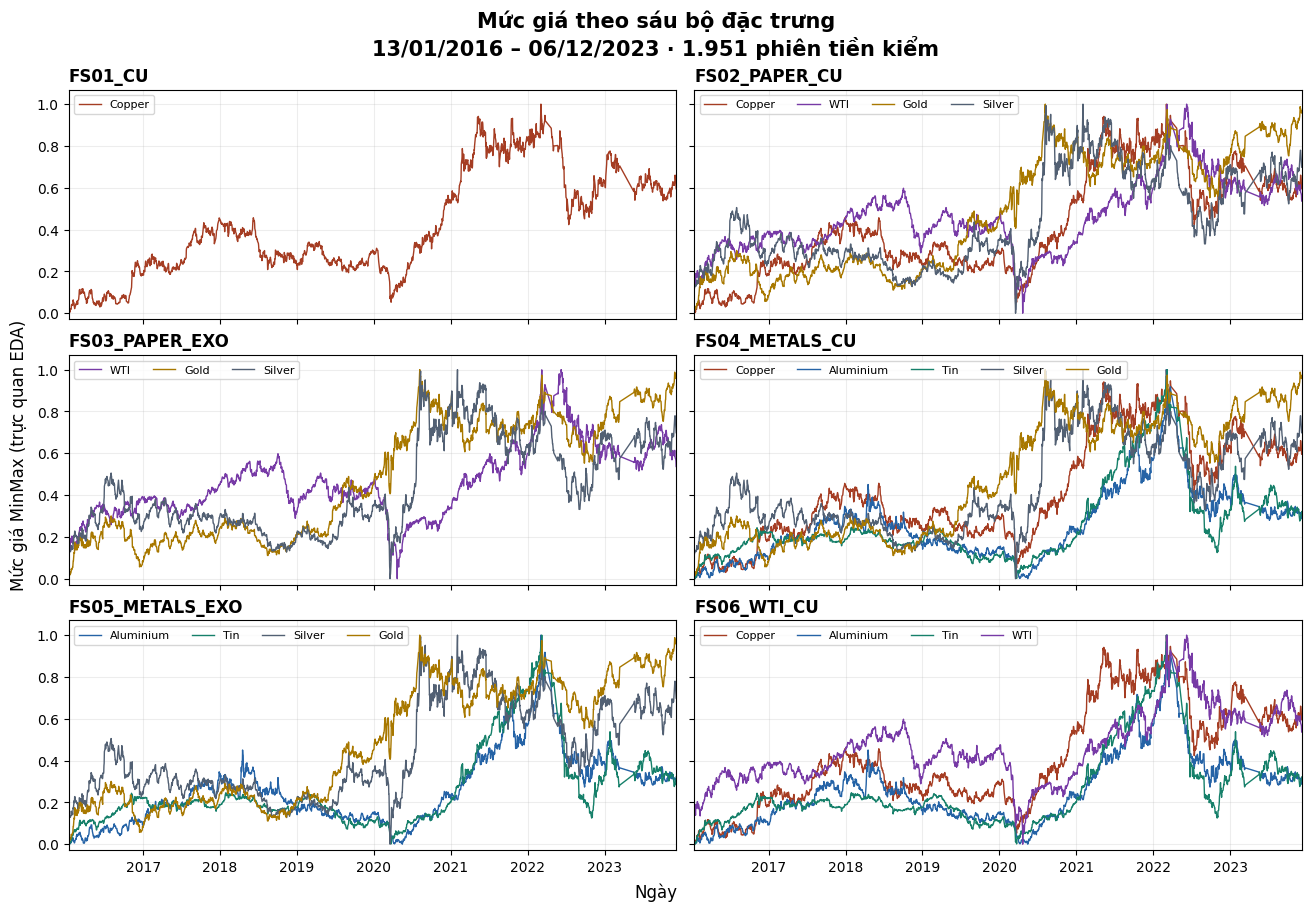

In [58]:
feature_sets_eda = {
    "FS01_CU":         ["Copper"],
    "FS02_PAPER_CU":   ["Copper", "WTI", "Gold", "Silver"],
    "FS03_PAPER_EXO":  ["WTI", "Gold", "Silver"],
    "FS04_METALS_CU":  ["Copper", "Aluminium", "Tin", "Silver", "Gold"],
    "FS05_METALS_EXO": ["Aluminium", "Tin", "Silver", "Gold"],
    "FS06_WTI_CU":     ["Copper", "Aluminium", "Tin", "WTI"],
}
commodity_colors = {
    "Copper": "#A53D23", "Aluminium": "#2563A6", "Tin": "#16806A",
    "WTI": "#773AA6", "Gold": "#A87800", "Silver": "#526073",
}

eda_prices = train_eda[FEATURES]
eda_min = eda_prices.min()
eda_span = eda_prices.max() - eda_min
eda_scaled = (eda_prices - eda_min).div(eda_span.replace(0, 1))
eda_dates = train_eda["Date"]
eda_period = f"{eda_dates.iloc[0]:%d/%m/%Y} – {eda_dates.iloc[-1]:%d/%m/%Y}"

fig, axes = plt.subplots(3, 2, figsize=(13, 9), sharex=True, sharey=True, layout="constrained")
for ax, (fs_name, cols) in zip(axes.flat, feature_sets_eda.items()):
    for col in cols:
        ax.plot(eda_dates, eda_scaled[col], label=col, color=commodity_colors[col], linewidth=1)
    ax.set_title(fs_name, loc="left", fontweight="bold")
    ax.legend(loc="upper left", ncol=len(cols), fontsize=8)
    ax.grid(alpha=0.22)
    ax.set_xlim(eda_dates.iloc[0], eda_dates.iloc[-1])
    ax.set_ylim(-0.03, 1.07)
eda_count_label = f"{len(train_eda):,}".replace(",", ".")
fig.suptitle(f"Mức giá theo sáu bộ đặc trưng\n{eda_period} · {eda_count_label} phiên tiền kiểm",
             fontsize=15, fontweight="bold")
fig.supxlabel("Ngày")
fig.supylabel("Mức giá MinMax (trực quan EDA)")
fig.savefig(OUT / "01_feature_sets_minmax.png", dpi=200)
plt.show()

## 3. Kiểm định 1 — Tính dừng chuỗi thời gian (ADF + KPSS)
- **ADF** ($H_0$: chuỗi có nghiệm đơn vị / không dừng) và **KPSS** ($H_0$: chuỗi dừng quanh hằng số).
- Mục đích: Xác minh mức giá gốc không dừng và sai phân bậc 1 dừng — cơ sở thiết kế nhánh **Residual** (`ΔCopper`).

In [59]:
station_rows = []
for col in FEATURES:
    for transform_name, series in [
        ("level", train_eda[col]),
        ("difference", diff_eda[col]),
        ("simple_return", ret_eda[col]),
    ]:
        x = pd.to_numeric(series, errors="coerce").dropna()
        adf_res = adfuller(x, autolag="AIC", regression="c")
        kpss_res = kpss(x, regression="c", nlags="auto")
        station_rows.append({
            "feature": col,
            "transform": transform_name,
            "n": len(x),
            "adf_stat": float(adf_res[0]),
            "adf_p": float(adf_res[1]),
            "adf_lags": int(adf_res[2]),
            "kpss_stat": float(kpss_res[0]),
            "kpss_p": float(kpss_res[1]),
            "kpss_lags": int(kpss_res[2]),
        })

station_df = pd.DataFrame(station_rows)
station_df.to_csv(OUT / "02_adf_kpss.csv", index=False)
display(station_df.round(5))

,feature,transform,n,adf_stat,adf_p,adf_lags,kpss_stat,kpss_p,kpss_lags
0,Copper,level,1951,-1.69898,0.43164,7,4.64128,0.01,27
1,Copper,difference,1950,-17.21792,0.00000,6,0.07312,0.10,0
2,Copper,simple_return,1950,-16.58410,0.00000,6,0.09463,0.10,2
3,Aluminium,level,1951,-2.05029,0.26497,12,2.99752,0.01,27
4,Aluminium,difference,1950,-12.08077,0.00000,11,0.09326,0.10,12
5,Aluminium,simple_return,1950,-26.38401,0.00000,2,0.10780,0.10,8
6,Tin,level,1951,-1.97857,0.29605,25,2.70509,0.01,27
7,Tin,difference,1950,-7.20863,0.00000,24,0.12626,0.10,5
8,Tin,simple_return,1950,-7.64882,0.00000,24,0.14327,0.10,0
9,WTI,level,1951,-2.37194,0.14981,25,3.18018,0.01,27


## 4. Kiểm định 2 — Tương quan mức giá (Spearman) vs. Lợi suất có độ trễ (BH-FDR)
- Đối chiếu tương quan đồng thời trên mức giá (có nguy cơ tương quan giả) với 30 phép kiểm định lợi suất có độ trễ (`lags = 1, 2, 5, 10, 22, 50`) đã hiệu chỉnh đa kiểm định **Benjamini–Hochberg (BH-FDR)**.

,Copper,Aluminium,Tin,WTI,Gold,Silver
Copper,1.0000,0.9170,0.8427,0.7546,0.6831,0.6695
Aluminium,0.9170,1.0000,0.8706,0.8474,0.4657,0.4956
Tin,0.8427,0.8706,1.0000,0.7409,0.4474,0.5324
WTI,0.7546,0.8474,0.7409,1.0000,0.3940,0.3289
Gold,0.6831,0.4657,0.4474,0.3940,1.0000,0.8274
Silver,0.6695,0.4956,0.5324,0.3289,0.8274,1.0000


,feature,lag,n,pearson_r,pearson_p,spearman_r,spearman_p,spearman_p_fdr_bh,pearson_p_fdr_bh
18,Gold,1,1949,0.06595,0.00358,0.09309,0.00004,0.00116,0.06882


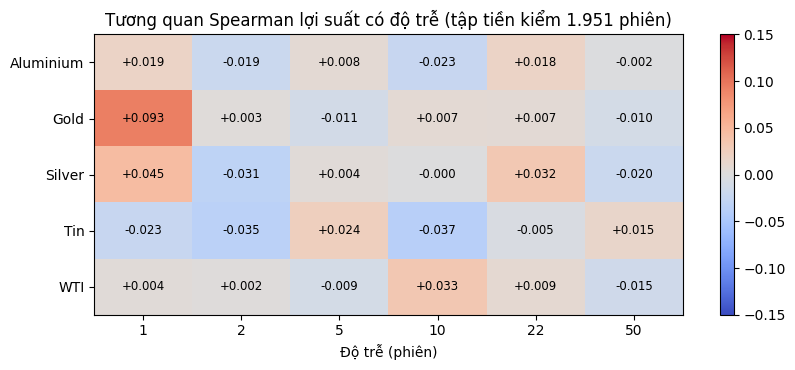

In [60]:
level_spearman = train_eda[FEATURES].corr(method="spearman")
level_spearman.to_csv(OUT / "03_spearman_levels_train.csv")

lag_rows = []
for exog in FEATURES[1:]:
    for lag in LAGS_CORR:
        pair = pd.DataFrame({"target": ret_eda["Copper"], "driver": ret_eda[exog].shift(lag)}).dropna()
        pr = stats.pearsonr(pair["driver"], pair["target"])
        sr = stats.spearmanr(pair["driver"], pair["target"])
        lag_rows.append({
            "feature": exog,
            "lag": lag,
            "n": len(pair),
            "pearson_r": float(pr.statistic),
            "pearson_p": float(pr.pvalue),
            "spearman_r": float(sr.statistic),
            "spearman_p": float(sr.pvalue),
        })

lagged_df = pd.DataFrame(lag_rows)
lagged_df["spearman_p_fdr_bh"] = multipletests(lagged_df["spearman_p"], method="fdr_bh")[1]
lagged_df["pearson_p_fdr_bh"] = multipletests(lagged_df["pearson_p"], method="fdr_bh")[1]
lagged_df.to_csv(OUT / "03_lagged_returns_correlations_FDR.csv", index=False)

display(level_spearman.round(4))
display(lagged_df[lagged_df["spearman_p_fdr_bh"] < 0.10].round(5))

# Vẽ bản đồ nhiệt tương quan Spearman có độ trễ
mat = lagged_df.pivot(index="feature", columns="lag", values="spearman_r")
fig, ax = plt.subplots(figsize=(8.5, 3.8))
im = ax.imshow(mat, aspect="auto", vmin=-0.15, vmax=0.15, cmap="coolwarm")
ax.set_xticks(range(len(mat.columns)), mat.columns)
ax.set_yticks(range(len(mat.index)), mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, f"{mat.iloc[i, j]:+.3f}", ha="center", va="center", fontsize=8.5)
ax.set_xlabel("Độ trễ (phiên)")
ax.set_title("Tương quan Spearman lợi suất có độ trễ (tập tiền kiểm 1.951 phiên)")
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(OUT / "03_spearman_lagged_heatmap.png", dpi=150)
plt.show()

### Cách đọc heatmap ở mục 4

Mỗi ô là hệ số Spearman giữa lợi suất hàng hóa ở phiên \(t-k\) và lợi suất Copper ở phiên \(t\). Dấu và sắc độ cho biết chiều và cường độ liên hệ đơn điệu. Đối chiếu cột `spearman_p_fdr_bh` trong CSV để đánh giá bằng chứng sau hiệu chỉnh.

## 5. Kiểm định 3 — Biến động phương sai 2 giai đoạn (Brown–Forsythe)
- So sánh phương sai lợi suất giữa 2 nửa bằng nhau của tập tiền kiểm (975 vs. 975 phiên, `center='median'`), tạo cơ sở thử nghiệm **Rolling 756**, **Recency-weighted** và **Walk-Forward**.

In [61]:
bf_rows = []
for col in FEATURES:
    rr_s = ret_eda[col].dropna()
    rr = rr_s.to_numpy()
    rr_dates = train_eda.loc[rr_s.index, "Date"].reset_index(drop=True)
    mid = len(rr) // 2
    bf_stat, bf_p = stats.levene(rr[:mid], rr[mid:], center="median")
    std_1 = float(np.std(rr[:mid], ddof=1))
    std_2 = float(np.std(rr[mid:], ddof=1))
    bf_rows.append({
        "feature": col,
        "n_first": mid,
        "n_second": len(rr) - mid,
        "first_period_end": str(rr_dates.iloc[mid - 1].date()),
        "second_period_start": str(rr_dates.iloc[mid].date()),
        "std_first": std_1,
        "std_second": std_2,
        "std_change_pct": 100.0 * (std_2 - std_1) / std_1,
        "bf_stat": float(bf_stat),
        "bf_p": float(bf_p),
    })

bf_df = pd.DataFrame(bf_rows)
bf_df["p_fdr_bh"] = multipletests(bf_df["bf_p"], method="fdr_bh")[1]
bf_df.to_csv(OUT / "04_brown_forsythe_variance.csv", index=False)
display(bf_df.round(5))

,feature,n_first,n_second,first_period_end,second_period_start,std_first,std_second,std_change_pct,bf_stat,bf_p,p_fdr_bh
0,Copper,975,975,2019-11-12,2019-11-13,0.01185,0.01521,28.32821,38.47467,0.00000,0.00000
1,Aluminium,975,975,2019-11-12,2019-11-13,0.01098,0.01449,31.93388,33.09145,0.00000,0.00000
2,Tin,975,975,2019-11-12,2019-11-13,0.00993,0.01893,90.67759,119.57102,0.00000,0.00000
3,WTI,975,975,2019-11-12,2019-11-13,0.02208,0.04290,94.29494,20.40743,0.00001,0.00001
4,Gold,975,975,2019-11-12,2019-11-13,0.00774,0.01027,32.72694,27.06739,0.00000,0.00000
5,Silver,975,975,2019-11-12,2019-11-13,0.01290,0.02196,70.22359,67.77606,0.00000,0.00000


### 5.1. Cách đọc boxplot lợi suất Copper

Mỗi hộp là một nửa theo đúng cách chia của Brown–Forsythe, sau khi bỏ giá trị thiếu của lợi suất đầu tiên. Đường trong hộp là median, hai mép là Q1 và Q3, chiều cao hộp là IQR = Q3 − Q1. Hai râu kết thúc ở các quan sát xa nhất còn trong giới hạn Q1 − 1,5 × IQR và Q3 + 1,5 × IQR. Chấm ngoài râu là những phiên nên xem lại. Mục 7 gắn cờ theo quy tắc riêng `|Robust-Z| > 3.5` trên toàn bộ chuỗi tiền kiểm.

So sánh độ cao hộp và râu để mô tả độ phân tán. Đọc thống kê và p-value Brown–Forsythe trong bảng để đánh giá bằng chứng về khác biệt phương sai.

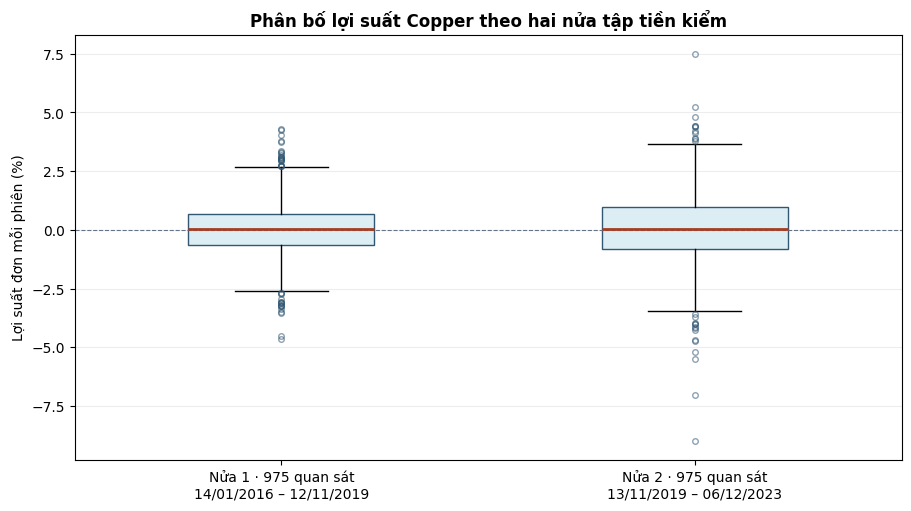

In [62]:
copper_returns_pct = 100 * ret_eda["Copper"].dropna()
mid = len(copper_returns_pct) // 2
copper_halves = (copper_returns_pct.iloc[:mid], copper_returns_pct.iloc[mid:])

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.boxplot(
    copper_halves, whis=1.5, showfliers=True, widths=0.45, patch_artist=True,
    boxprops={"facecolor": "#DCEEF4", "edgecolor": "#315772"},
    medianprops={"color": "#A53D23", "linewidth": 2},
    flierprops={"marker": "o", "markersize": 4, "markerfacecolor": "none",
                "markeredgecolor": "#315772", "alpha": 0.55},
)
labels = []
for i, half in enumerate(copper_halves, start=1):
    dates = train_eda.loc[half.index, "Date"]
    labels.append(f"Nửa {i} · {len(half)} quan sát\n{dates.iloc[0]:%d/%m/%Y} – {dates.iloc[-1]:%d/%m/%Y}")
ax.set_xticks([1, 2], labels)
ax.axhline(0, color="#64748B", linestyle="--", linewidth=0.8)
ax.set_title("Phân bố lợi suất Copper theo hai nửa tập tiền kiểm", fontweight="bold")
ax.set_ylabel("Lợi suất đơn mỗi phiên (%)")
ax.grid(axis="y", alpha=0.22)
fig.savefig(OUT / "04_copper_returns_boxplot.png", dpi=200)
plt.show()

## 6. Kiểm định 4 — Tự tương quan & cụm biến động (Ljung–Box + ARCH-LM)
- Kiểm tra tự tương quan trên lợi suất (`returns`), bình phương lợi suất (`returns²`) và hiệu ứng ARCH tại các độ trễ 5, 10, 22 phiên.

,feature,lag,lb_stat,lb_p,lb_sq_stat,lb_sq_p,arch_lm_stat,arch_lm_p
0,Copper,5,4.584065,0.468715,41.014980,0.000000,35.487416,0.000001
1,Copper,10,19.591264,0.033364,58.022599,0.000000,42.556791,0.000006
2,Copper,22,35.334631,0.035736,70.554764,0.000001,49.265623,0.000736


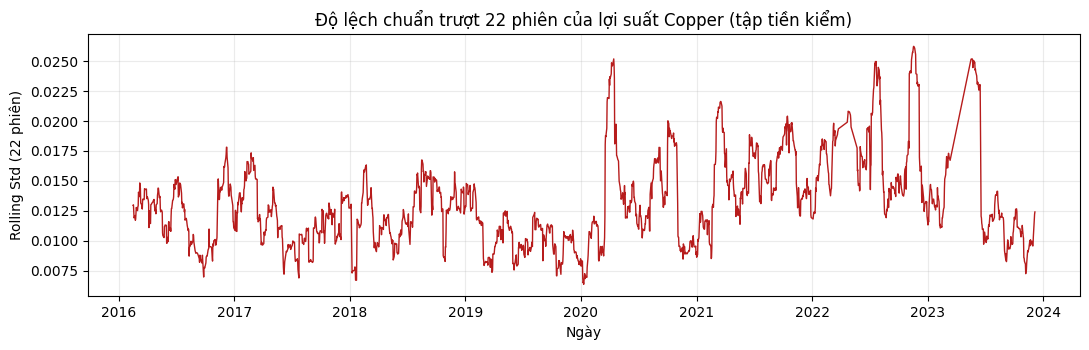

In [63]:
diag_rows = []
for col in FEATURES:
    x = ret_eda[col].dropna()
    for lag in LAGS_DIAG:
        lb = acorr_ljungbox(x, lags=[lag], return_df=True).iloc[0]
        lb2 = acorr_ljungbox(x ** 2, lags=[lag], return_df=True).iloc[0]
        arch_stat, arch_p, _, _ = het_arch(x, nlags=lag)
        diag_rows.append({
            "feature": col,
            "lag": lag,
            "lb_stat": float(lb["lb_stat"]),
            "lb_p": float(lb["lb_pvalue"]),
            "lb_sq_stat": float(lb2["lb_stat"]),
            "lb_sq_p": float(lb2["lb_pvalue"]),
            "arch_lm_stat": float(arch_stat),
            "arch_lm_p": float(arch_p),
        })

diag_df = pd.DataFrame(diag_rows)
diag_df.to_csv(OUT / "05_ljungbox_arch.csv", index=False)
display(diag_df[diag_df["feature"] == "Copper"].round(6))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(train_eda["Date"], ret_eda["Copper"].rolling(22).std(), lw=1.0, color="#B71C1C")
ax.set_title("Độ lệch chuẩn trượt 22 phiên của lợi suất Copper (tập tiền kiểm)")
ax.set_xlabel("Ngày")
ax.set_ylabel("Rolling Std (22 phiên)")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "05_copper_rolling_volatility.png", dpi=150)
plt.show()

### Cách đọc độ lệch chuẩn trượt ở mục 6

Mỗi điểm dùng tối đa 22 phiên đến ngày đang xét và chỉ xuất hiện khi đủ 22 lợi suất. Đỉnh cho thấy giai đoạn lợi suất phân tán mạnh. Những đoạn cao kéo dài gợi ý cụm biến động. Trục Y dùng lợi suất dạng tỷ lệ, chẳng hạn 0,02 ứng với 2%.

## 7. Kiểm định 5 — Phân phối đuôi dày & ngoại lệ (Jarque–Bera + Robust-Z)
- Kiểm tra tính chuẩn của lợi suất và đếm số phiên biến động cực đoan (`|Robust-Z| > 3.5`). Không xóa ngoại lệ để bảo toàn cú sốc thị trường thực tế và ưu tiên **MAE** song song RMSE.

,feature,n,mean,std,skew,excess_kurtosis,extreme_robust_z_gt_3_5,jb_stat,jb_p
0,Copper,1950,0.00042,0.01363,-0.16766,2.45403,23,4.984468e+02,0.0
1,Aluminium,1950,0.00028,0.01285,-0.03280,4.69640,28,1.792414e+03,0.0
2,Tin,1950,0.00043,0.01511,-1.01370,10.40036,75,9.122571e+03,0.0
3,WTI,1950,0.00098,0.03411,5.13531,163.59566,43,2.183108e+06,0.0
4,Gold,1950,0.00036,0.00909,0.06965,5.34893,69,2.326221e+03,0.0
5,Silver,1950,0.00044,0.01801,-0.56492,13.00596,110,1.384757e+04,0.0


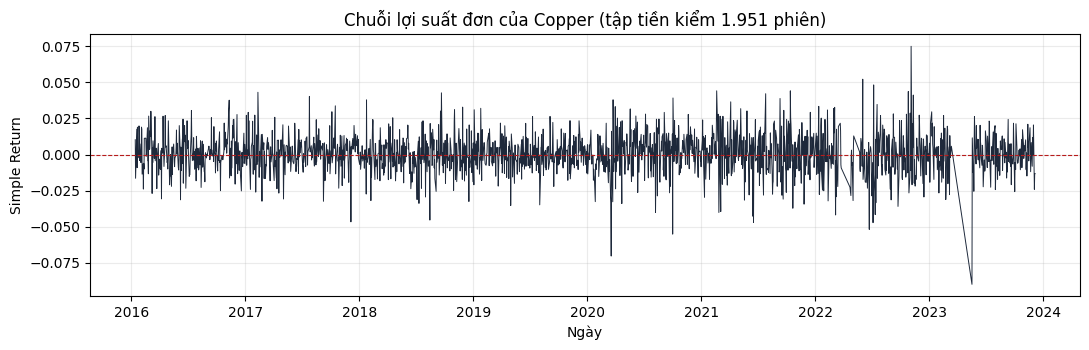

In [64]:
jb_rows = []
for col in FEATURES:
    x = ret_eda[col].dropna()
    med = x.median()
    mad = np.median(np.abs(x - med))
    robust_z = 0.67448975 * (x - med) / mad if mad > 0 else pd.Series(np.nan, index=x.index)
    jb = stats.jarque_bera(x)
    jb_rows.append({
        "feature": col,
        "n": len(x),
        "mean": float(x.mean()),
        "std": float(x.std()),
        "skew": float(stats.skew(x)),
        "excess_kurtosis": float(stats.kurtosis(x)),
        "extreme_robust_z_gt_3_5": int((np.abs(robust_z) > 3.5).sum()),
        "jb_stat": float(jb.statistic),
        "jb_p": float(jb.pvalue),
    })

jb_df = pd.DataFrame(jb_rows)
jb_df.to_csv(OUT / "06_jarque_bera_outliers.csv", index=False)
display(jb_df.round(5))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(train_eda["Date"], ret_eda["Copper"], lw=0.7, color="#1E293B")
ax.axhline(0, color="#B71C1C", lw=0.8, ls="--")
ax.set_title("Chuỗi lợi suất đơn của Copper (tập tiền kiểm 1.951 phiên)")
ax.set_xlabel("Ngày")
ax.set_ylabel("Simple Return")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "06_copper_returns.png", dpi=150)
plt.show()

### Cách đọc chuỗi lợi suất ở mục 7

Điểm trên và dưới đường 0 lần lượt là phiên tăng và giảm so với phiên trước trong CSV. Trục Y dùng tỷ lệ, chẳng hạn −0,05 tương ứng −5%. Đối chiếu các phiên có biên độ lớn với quy tắc robust-z và bảng Jarque–Bera để phân biệt gắn cờ từng phiên với kiểm định phân phối.

## 8. Xuất manifest & đóng gói `01_eda_results.zip`

In [65]:
manifest = {
    "notebook": "01_EDA_va_Kiem_Dinh_Thong_Ke.ipynb",
    "dataset_sha256": actual_sha,
    "all_rows": len(df),
    "eda_train_rows": eda_cut,
    "eda_train_last_date": str(train_eda["Date"].iloc[-1].date()),
    "split_80_test_start": str(df["Date"].iloc[split_80].date()),
    "leakage_audit_passed": True,
    "core_tests": [
        "ADF + KPSS",
        "Spearman Levels vs Lagged Returns (BH-FDR)",
        "Brown-Forsythe Two-Half Variance",
        "Ljung-Box (r, r^2) + ARCH-LM",
        "Jarque-Bera + Robust-Z (>3.5)",
    ],
    "versions": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scipy": scipy.__version__,
        "statsmodels": sm.__version__,
    },
}
(OUT / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")

zip_path = OUT.parent / "01_eda_results.zip"
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for f in sorted(OUT.iterdir()):
        if f.is_file():
            zf.write(f, arcname=f.name)

print(f"HOÀN TẤT: {zip_path} ({zip_path.stat().st_size / 1024:.1f} KB)")

HOÀN TẤT: /kaggle/working/01_eda_results.zip (1359.1 KB)
